# 02. 가설1 검증 — 침체기 가입자는 참여를 덜 시작하는가 (유입 질)

**요약**

- **H1 지지.** 가입 후 90일 안에 참여·창작을 시작한 비율이 **12.71% → 3.61%** (상대 −71.6%, 95% CI −71.8 ~ −71.5%). 5%·10% 기준 모두 통과.
- 가입자는 2.9배인데 활동을 시작한 인원은 **25.9만 → 21.4만 명**으로 줄었다.
- **가장 크게 무너진 입구는 대회 참가** (11.28% → 2.77%, −75.5%). 활동을 시작한 유저 안에서도 "창작 먼저" 비중이 18.4% → 30.5%로 늘었다.
- **차이의 57%는 가입 당일에 이미 벌어진다** (당일 활동 6.80% → 1.62%). 가입 후 시간이 지나도 격차가 좁혀지지 않는다.
- 활동 정의를 넓혀도(가벼운 활동 포함) −63%로 같은 결론.
- 대안 설명: 이벤트성 가입 → 배제, 국가 구성 → 데이터 한계로 분해 불가, 측정 밖 활동 → 관여 자체가 줄어 일부만 설명, 상금 대회 공급 감소(−34%) → 일부 기여 가능하나 하락 폭(−75%)을 설명 못 함.

| 섹션 | 내용 |
|---|---|
| §1 | 주 지표: 90일 활성화율 판정 (기준은 `01` §6에서 고정) |
| §2 | 보조 지표: 가입 당일 활동, 대회 참가, 창작, 첫 활동 유형, 활성화 속도 |
| §3 | 견고성: 가벼운 활동까지 포함한 정의 |
| §4 | 대안 설명: 이벤트성 가입, 국가 구성, 측정 밖 활동, 대회 공급, 봇 |

입력: `data/processed/h1_cohort.parquet`, `h1_competitions.parquet` (`scripts/02_h1_cohort.py`)

In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint, confint_proportions_2indep

sys.path.append("../src")
sys.path.append(os.path.expanduser("~/.claude/skills/chart-style"))
from metakaggle.config import processed
import viz_style as vs

vs.setup()
FIG = "../docs/figures"
df = pd.read_parquet(processed("h1_cohort"))
df["period"] = df.period.astype("category")
df["reg"] = pd.to_datetime(df.reg)
comp = pd.read_parquet(processed("h1_competitions"))
G, S = df.period == "Golden", df.period == "Stagnation"
N = {"Golden": int(G.sum()), "Stagnation": int(S.sum())}
N

{'Golden': 2041992, 'Stagnation': 5943573}

## §1 주 지표: 90일 활성화율

- **정의**: 가입 후 90일 안에 QAU 활동(팀 합류 또는 창작)을 처음 한 비율
- **판정** (`01` §6에서 고정): 침체기/황금기 비율의 95% CI 상한이 0.95 미만이면 5% 기준 지지, 0.90 미만이면 10% 기준 지지. CI가 [0.95, 1.05] 안이면 기각(동등)
- **CI**: 비율은 Wilson, 두 비율의 차이는 Newcombe, 비율의 배수는 log 위험비

In [2]:
def compare(flag, name):
    xg, xs = int(flag[G].sum()), int(flag[S].sum())
    ng, ns = N["Golden"], N["Stagnation"]
    lo_g, hi_g = proportion_confint(xg, ng, method="wilson"); lo_s, hi_s = proportion_confint(xs, ns, method="wilson")
    r_lo, r_hi = confint_proportions_2indep(xs, ns, xg, ng, method="log", compare="ratio")
    d_lo, d_hi = confint_proportions_2indep(xs, ns, xg, ng, method="newcomb", compare="diff")
    ratio = (xs / ns) / (xg / ng)
    return pd.Series({"황금기": xg / ng, "침체기": xs / ns, "차이 (%p)": (xs / ns - xg / ng) * 100,
                      "차이 95% CI": f"[{d_lo*100:+.2f}, {d_hi*100:+.2f}]",
                      "상대 차이": ratio - 1, "상대 차이 95% CI": f"[{r_lo-1:+.1%}, {r_hi-1:+.1%}]",
                      "5% 기준": "지지" if r_hi < 0.95 else ("기각(동등)" if r_lo > 0.95 and r_hi < 1.05 else "판정 불가"),
                      "10% 기준": "지지" if r_hi < 0.90 else ("기각(동등)" if r_lo > 0.90 and r_hi < 1.10 else "판정 불가"),
                      "황금기 인원": xg, "침체기 인원": xs}, name=name)

fmt = {"황금기": "{:.2%}", "침체기": "{:.2%}", "차이 (%p)": "{:+.2f}", "상대 차이": "{:+.1%}", "황금기 인원": "{:,}", "침체기 인원": "{:,}"}
main = compare(df.first_qau <= 90, "90일 활성화율").to_frame().T
main.style.format(fmt)

,황금기,침체기,차이 (%p),차이 95% CI,상대 차이,상대 차이 95% CI,5% 기준,10% 기준,황금기 인원,침체기 인원
90일 활성화율,12.71%,3.61%,-9.11,"[-9.15, -9.06]",-71.6%,"[-71.8%, -71.5%]",지지,지지,"259,568","214,286"


**H1 지지 (5%·10% 기준 모두).** 가입자는 2.9배인데 90일 안에 활동을 시작한 인원은 오히려 줄었다.

## §2 보조 지표

In [3]:
metrics = {
    "가입 당일 활동 (QAU)": df.first_qau <= 0,
    "90일 내 대회 참가 (팀 합류)": df.first_team <= 90,
    "90일 내 창작": df.first_creator <= 90,
}
sub = pd.DataFrame([compare(f, n) for n, f in metrics.items()])
sub.style.format(fmt)

,황금기,침체기,차이 (%p),차이 95% CI,상대 차이,상대 차이 95% CI,5% 기준,10% 기준,황금기 인원,침체기 인원
가입 당일 활동 (QAU),6.80%,1.62%,-5.19,"[-5.22, -5.15]",-76.2%,"[-76.4%, -76.0%]",지지,지지,"138,925","96,160"
90일 내 대회 참가 (팀 합류),11.28%,2.77%,-8.51,"[-8.56, -8.47]",-75.5%,"[-75.6%, -75.3%]",지지,지지,"230,293","164,340"
90일 내 창작,3.50%,1.37%,-2.13,"[-2.16, -2.11]",-60.9%,"[-61.3%, -60.6%]",지지,지지,"71,473","81,247"


In [4]:
# 첫 활동 유형: 90일 안에 활동을 시작한 유저가 무엇부터 했나
act = df[df.first_qau <= 90]
first_type = np.where(act.first_creator.fillna(np.inf) <= act.first_team.fillna(np.inf), "창작 먼저", "대회 참가(팀 합류) 먼저")
ft = pd.crosstab(act.period, first_type, normalize="index")
ft.style.format("{:.1%}")

col_0,대회 참가(팀 합류) 먼저,창작 먼저
period,,
Golden,81.6%,18.4%
Stagnation,69.5%,30.5%


[]


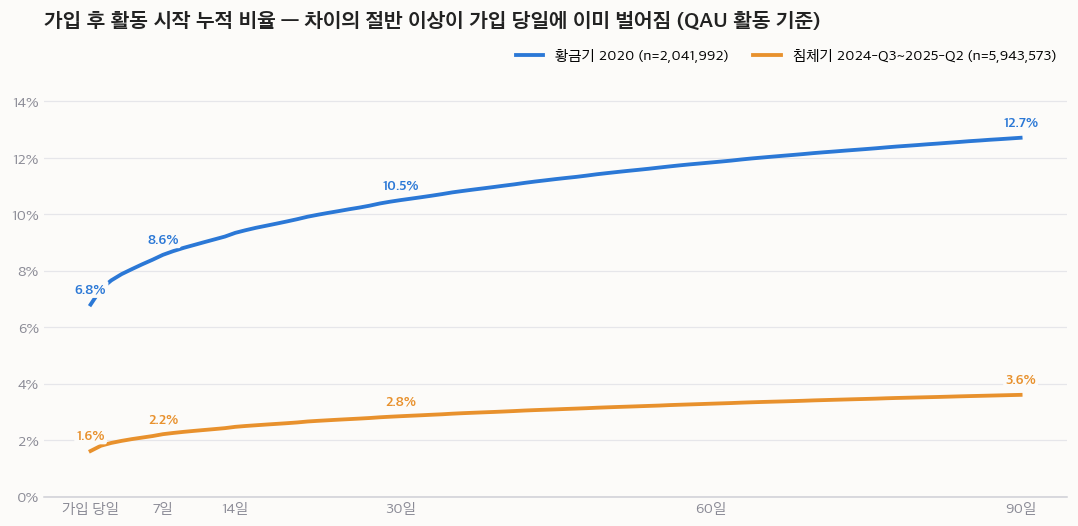

In [5]:
# 활성화 속도: 가입 후 n일까지 활동을 시작한 누적 비율
days = np.arange(0, 91)
cum = {p: np.array([(df.loc[df.period == p, "first_qau"] <= d).mean() for d in days]) for p in ["Golden", "Stagnation"]}
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(days, cum["Golden"], color=vs.BLUE, lw=2.5, label=vs.n_label("황금기 2020", N["Golden"]))
ax.plot(days, cum["Stagnation"], color=vs.ORANGE, lw=2.5, label=vs.n_label("침체기 2024-Q3~2025-Q2", N["Stagnation"]))
for d in [0, 7, 30, 90]:
    for p, c in [("Golden", vs.BLUE), ("Stagnation", vs.ORANGE)]:
        ax.annotate(f"{cum[p][d]:.1%}", (d, cum[p][d]), xytext=(0, 7), textcoords="offset points", ha="center",
                    color=c, fontsize=9, fontweight="bold", bbox=vs.LABEL_BOX)
vs.yfmt(ax, lambda v: f"{v:.0%}"); ax.set_xticks([0, 7, 14, 30, 60, 90]); ax.set_xticklabels(["가입 당일", "7일", "14일", "30일", "60일", "90일"])
ax.set_ylim(0, 0.15)
ax.set_title("가입 후 활동 시작 누적 비율 — 차이의 절반 이상이 가입 당일에 이미 벌어짐 (QAU 활동 기준)", loc="left", fontweight="bold")
vs.legend_top_right(ax)
fig.savefig(f"{FIG}/02_activation_curve.png", dpi=120, bbox_inches="tight")
print(vs.check_overlaps(fig))

## §3 견고성: 활동 정의를 넓혀도 같은가

QAU 정의는 투표·팔로우·반응을 뺐다. 가벼운 활동까지 "시작"으로 쳐도 하락이 유지되는지 본다.

In [6]:
robust = pd.DataFrame([
    compare(df.first_qau <= 90, "QAU 활동 (주 지표)"),
    compare(df.first_light <= 90, "가벼운 활동만 (투표·팔로우·반응)"),
    compare((df.first_qau <= 90) | (df.first_light <= 90), "QAU 또는 가벼운 활동"),
])
robust.style.format(fmt)

,황금기,침체기,차이 (%p),차이 95% CI,상대 차이,상대 차이 95% CI,5% 기준,10% 기준,황금기 인원,침체기 인원
QAU 활동 (주 지표),12.71%,3.61%,-9.11,"[-9.15, -9.06]",-71.6%,"[-71.8%, -71.5%]",지지,지지,"259,568","214,286"
가벼운 활동만 (투표·팔로우·반응),5.79%,3.03%,-2.76,"[-2.80, -2.73]",-47.7%,"[-48.1%, -47.3%]",지지,지지,"118,272","180,106"
QAU 또는 가벼운 활동,16.84%,6.23%,-10.61,"[-10.67, -10.56]",-63.0%,"[-63.2%, -62.9%]",지지,지지,"343,818","369,990"


[]


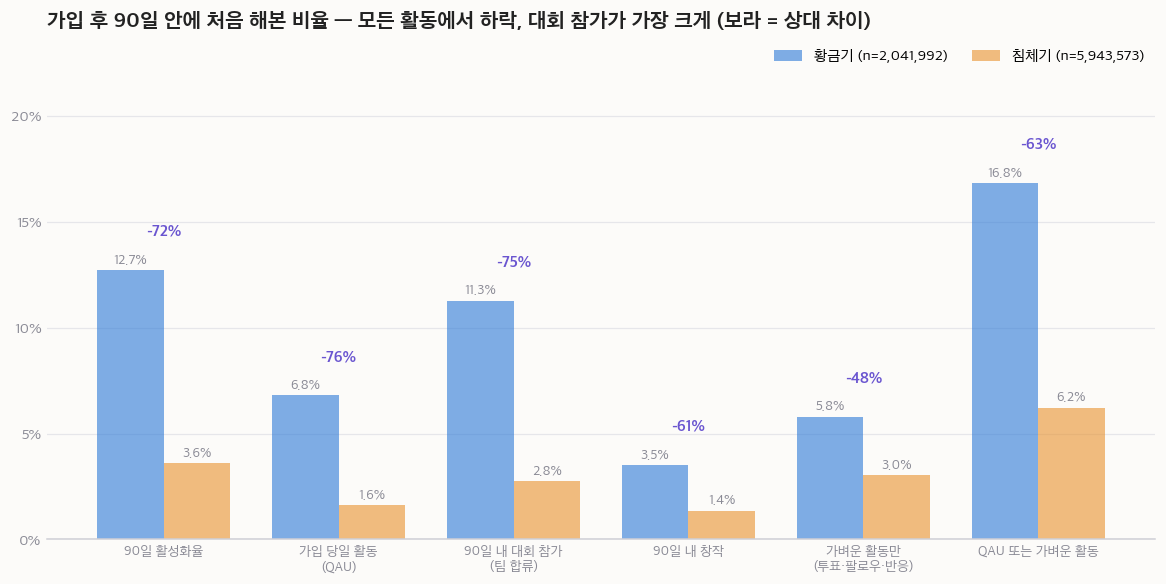

In [7]:
# 주 지표 + 보조 + 견고성을 한 그림으로
allm = pd.concat([main, sub, robust.iloc[1:]])
order = ["90일 활성화율", "가입 당일 활동 (QAU)", "90일 내 대회 참가 (팀 합류)", "90일 내 창작", "가벼운 활동만 (투표·팔로우·반응)", "QAU 또는 가벼운 활동"]
allm = allm.loc[order]
x = np.arange(len(allm)); w = 0.38
fig, ax = plt.subplots(figsize=(13, 5.5))
bg = ax.bar(x - w / 2, allm["황금기"].astype(float), w, color=vs.BLUE, alpha=0.6, label=vs.n_label("황금기", N["Golden"]))
bs = ax.bar(x + w / 2, allm["침체기"].astype(float), w, color=vs.ORANGE, alpha=0.6, label=vs.n_label("침체기", N["Stagnation"]))
vs.label_bars(ax, list(bg) + list(bs), fmt=lambda v: f"{v:.1%}")
for i, r in enumerate(allm["상대 차이"].astype(float)):
    ax.annotate(f"{r:+.0%}", (x[i], max(allm['황금기'].iloc[i], allm['침체기'].iloc[i])), xytext=(0, 22), textcoords="offset points",
                ha="center", color=vs.PURPLE, fontweight="bold", fontsize=10)
ax.set_xticks(x); ax.set_xticklabels([o.replace(" (", "\n(") for o in order], fontsize=9)
vs.yfmt(ax, lambda v: f"{v:.0%}"); ax.set_ylim(0, 0.22); ax.yaxis.set_major_locator(plt.MultipleLocator(0.05))
ax.set_title("가입 후 90일 안에 처음 해본 비율 — 모든 활동에서 하락, 대회 참가가 가장 크게 (보라 = 상대 차이)", loc="left", fontweight="bold")
vs.legend_top_right(ax)
fig.savefig(f"{FIG}/02_h1_metrics.png", dpi=120, bbox_inches="tight")
print(vs.check_overlaps(fig))

## §4 대안 설명: 정말 "가입자의 성격"이 바뀐 것인가

활성화율 하락은 유입 질 말고도 설명될 수 있다. 데이터로 확인할 수 있는 것부터 하나씩 본다.

### A. 이벤트성 가입이 늘었다
대규모 온라인 강의·행사 때 하루 가입자가 튀면, 그날 가입자는 목적이 달라 활성화율이 낮을 수 있다. 급증일 = 그날 가입자가 앞뒤 29일 중앙값의 1.3배를 넘는 날.

In [8]:
daily = df.groupby("reg").agg(n=("UserId", "size"), act=("first_qau", lambda s: (s <= 90).mean()), period=("period", "first"))
daily["ratio"] = daily.groupby("period").n.transform(lambda s: s / s.rolling(29, center=True, min_periods=10).median())
daily["spike"] = daily.ratio > 1.3
spike = daily.groupby(["period", "spike"]).apply(lambda t: pd.Series({"일수": len(t), "가입자 비중": t.n.sum(), "활성화율": np.average(t.act, weights=t.n)}))
spike["가입자 비중"] = spike["가입자 비중"] / spike.groupby(level=0)["가입자 비중"].transform("sum")
spike.style.format({"일수": "{:.0f}", "가입자 비중": "{:.1%}", "활성화율": "{:.2%}"})

[]


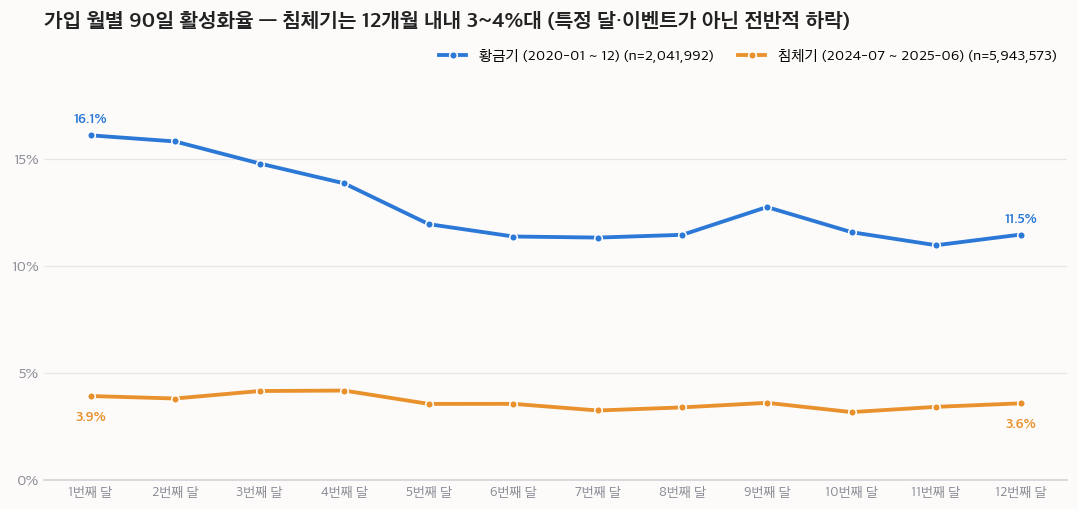

In [9]:
# 가입 월별 활성화율: 특정 달이 끌어내렸는지
mon = df.assign(m=df.reg.dt.month).groupby(["period", "m"]).agg(n=("UserId", "size"), act=("first_qau", lambda s: (s <= 90).mean())).reset_index()
fig, ax = plt.subplots(figsize=(12, 4.8))
for p, c, lab in [("Golden", vs.BLUE, "황금기 (2020-01 ~ 12)"), ("Stagnation", vs.ORANGE, "침체기 (2024-07 ~ 2025-06)")]:
    t = mon[mon.period == p].copy()
    order_m = list(range(1, 13)) if p == "Golden" else list(range(7, 13)) + list(range(1, 7))
    t = t.set_index("m").loc[order_m]
    vs.line(ax, np.arange(12), t.act.values, c, vs.n_label(lab, int(t.n.sum())))
    for i in (0, 11):
        ax.annotate(f"{t.act.values[i]:.1%}", (i, t.act.values[i]), xytext=(0, 8 if p == "Golden" else -16), textcoords="offset points",
                    ha="center", color=c, fontsize=9, fontweight="bold", bbox=vs.LABEL_BOX)
ax.set_xticks(np.arange(12)); ax.set_xticklabels([f"{i}번째 달" for i in range(1, 13)], fontsize=9)
vs.yfmt(ax, lambda v: f"{v:.0%}"); ax.set_ylim(0, 0.19); ax.yaxis.set_major_locator(plt.MultipleLocator(0.05))
ax.set_title("가입 월별 90일 활성화율 — 침체기는 12개월 내내 3~4%대 (특정 달·이벤트가 아닌 전반적 하락)", loc="left", fontweight="bold")
vs.legend_top_right(ax)
fig.savefig(f"{FIG}/02_monthly_activation.png", dpi=120, bbox_inches="tight")
print(vs.check_overlaps(fig))

→ **배제.** 침체기 코호트 안의 급증일은 소수이고 그날 가입자의 활성화율도 평소와 같다. 12개월 모두 낮다.

### B. 국가 구성이 바뀌었다
활성화율이 낮은 국가의 가입이 늘었다면 하락은 "구성 효과"일 수 있다. 전체 변화 = 구성 효과(국가 비중 변화) + 국가 안 효과(같은 국가 안의 활성화율 변화)로 나눈다.

In [10]:
cty = df.assign(country=df.country.fillna("(미기재)"), act=df.first_qau <= 90)
c = cty.groupby(["country", "period"]).act.agg(["size", "mean"]).unstack()
w = c["size"].div(c["size"].sum()); r = c["mean"]
print(f"국가 미기재 비율: 황금기 {w.loc['(미기재)', 'Golden']:.1%}, 침체기 {w.loc['(미기재)', 'Stagnation']:.1%}")
both = r.Golden.notna() & r.Stagnation.notna()
total = (w.Stagnation.fillna(0) * r.Stagnation.fillna(0)).sum() - (w.Golden.fillna(0) * r.Golden.fillna(0)).sum()
mix = ((w.Stagnation - w.Golden) * (r.Golden + r.Stagnation) / 2)[both].sum()
within = ((r.Stagnation - r.Golden) * (w.Golden + w.Stagnation) / 2)[both].sum()
print(f"전체 {total*100:+.2f}%p = 구성 효과 {mix*100:+.2f}%p + 국가 안 효과 {within*100:+.2f}%p + 기타 {(total-mix-within)*100:+.2f}%p")

국가 미기재 비율: 황금기 95.6%, 침체기 99.1%
전체 -9.11%p = 구성 효과 -0.60%p + 국가 안 효과 -8.43%p + 기타 -0.08%p


→ **분해 불가 (데이터 한계).** 국가를 적은 가입자가 5% 미만이라 사실상 "미기재" 한 집단 안의 비교가 된다. 숫자상 구성 효과는 작지만 근거로 쓰지 않는다. 미기재 비율 자체가 오른 것(95.6% → 99.1%)은 프로필을 채우지 않는 가벼운 가입이 늘었다는 약한 신호다.

### C. 측정되지 않는 행동으로 옮겨갔다
강의 수강·데이터 다운로드처럼 기록이 없는 행동으로 옮겨갔다면, 기록되는 활동만 줄어 보인다. 직접 확인은 불가능하다. 대신 **가벼운 활동**(§3)을 보면: 관여가 그대로인데 행동만 옮겨갔다면 투표·팔로우는 유지돼야 한다.

→ **일부만 설명 가능.** 가벼운 활동도 크게 줄었다(§3). 관여 자체가 줄었다. 다만 기록이 아예 없는 행동은 배제할 수 없다.

### E. 대회 공급이 줄었다
대회 참가가 가장 크게 줄었으므로(§2), 참가할 대회 자체가 줄었는지 본다.

In [11]:
comp["구분"] = np.where(comp.segment.isin(["Featured", "Research"]), "상금 대회 (Featured·Research)", "기타 (Community·Playground 등)")
supply = comp.groupby(["구분", "period"]).agg(대회수=("Id", "size"), 참가팀합계=("total_teams", "sum"), 대회당참가팀중앙값=("total_teams", "median")).unstack()
supply.style.format("{:,.0f}")

→ **부분적으로만 가능.** 전체 참가 기회는 늘었다(커뮤니티 대회 참가 팀 2.3배). 하지만 신규 유저가 가장 많이 들어오는 **상금 대회는 44개 → 29개(−34%)**, 참가 팀 합계도 −26%로 줄었다. 대회당 참가 팀은 오히려 늘어(중앙값 +33%) 열린 대회의 인기는 유지됐다. 상금 대회 공급 감소가 신규 유저의 대회 참가 하락(−75%)의 일부를 설명할 수는 있지만, 하락 폭이 공급 감소 폭보다 훨씬 커서 전부를 설명하지는 못한다. (대회의 난이도·매력은 측정하지 않았다.)

### D. 봇·스팸 가입
가입자 중 봇을 가려낼 컬럼이 없다 (`PerformanceTier`는 99.9%가 기본값). **한계로 둔다.** 봇 가입이 늘었다면 그것도 유입 질 하락의 한 형태다.

## 결론

1. **신규 가입자의 성격이 바뀌었다.** 활성화율 하락은 특정 달·이벤트가 아니라 침체기 12개월 내내 3~4%대로 고르게 나타난다. 대회 공급이나 측정 범위의 변화로는 하락 폭을 설명할 수 없다.
2. **바뀐 핵심은 "대회 참가 의도"다.** 황금기 가입자의 11%가 90일 안에 대회에 참가했지만 침체기는 3% 미만이다. 반면 창작은 비율로는 줄었어도 인원은 7.1만 → 8.1만 명으로 늘었다. Kaggle에 오는 사람이 "대회 하러 오는 사람"에서 "다른 목적으로 오는 사람"으로 바뀌었다.
3. **격차는 가입 당일에 정해진다.** 첫날 활동하지 않은 사람이 나중에 따라잡지 않는다. 따라서 개입 지점은 가입 직후의 첫 경험이다.

**액션 (가설 수준, 검증 필요)**
- 유입 경로·목적별로 가입 직후 첫 활동을 다르게 설계 (예: 대회 목적이 아닌 가입자에게는 창작·학습 경로를 먼저 제시)
- 가입 당일 활동 여부를 핵심 선행 지표로 모니터링

**한계**: 유입 경로·가입 목적 데이터가 없어 "성격 변화"를 직접 관측하지 못하고 대안 설명을 배제하는 방식으로 추론했다. 국가 미기재 95% 이상, 봇 식별 불가, 강의 수강 같은 기록 밖 활동은 배제하지 못한다.

**다음**: H1이 지지됐으므로, 활동을 시작한 사람이 핵심 창작(D)까지 가는지(H2)를 `03`에서 본다. 침체기에는 걸러진 사람만 시작하므로 선택 편향을 함께 다룬다.